# Extra mile: automated court keypoints

**Author:** Ivayla Pernikova

**Goal:** *"Train a lightweight keypoint model ( YOLO Pose) to automate homography line detection."* In the MVP (notebook 05) the homography comes from 7 points clicked by hand on frame 1, which only works for this one camera. Here a YOLO26n-pose model finds 14 court landmarks in a frame, and the homography is fitted from them automatically.

**Result:** the final model, **K2** (every landmark its own object, YOLO26n-pose at 640 px, trained on a laptop CPU), gives the app a homography that is **0.07 m** off on average over the whole court (0.19 m at worst), against **0.52 m** (1.63 m at worst) for the MVP's hand-clicked one. Rider dots on the minimap go from 0.48 m to 0.05 m off. Using only validation frames, the clip's homography is 0.14 m off. On single validation images the median error is 0.10 m (frames as filmed) and 0.14 m (virtual-camera views), but a view where only a few landmarks are found can fail badly (section 12.2). The first design, K1 (the court as one object with 14 keypoints), squeezed the court by 8% towards its centre; section 9 traces that to how YOLO decodes keypoints, and K2 removes it (0.0%).

**How the notebook is organised (in the order the work was done):** labels (3-4) -> dataset (5) -> first two models K0 and K1 (6-8) -> what went wrong with K1 (9) -> the fix, K2 (10) -> hand-off to the app (11) -> error analysis (12) -> limits (13) -> every decision and why (14).

Code: `tools/measure_court_keypoints.py` (reference labels), `data/prepare_keypoint_dataset.py` (datasets), `app/core/court_keypoints.py` (landmarks to homography), `tools/auto_homography.py` (saves H for the app). Training is in this notebook.

## 0. Sources and GenAI use

**GenAI**

The code is written by Claude Code
- Prompts:
1. Our brief says ‘Train a lightweight keypoint model (e.g., YOLO Pose) to automate homography line detection.’ Read notebooks 05 and 07 and the app code, then propose 2-3 ways to do this and what each would need.
2. Which court landmarks could a keypoint model find? Look at the frame and tell me what’s visible.
3. How accurate is our clicked homography? Check it against the actual court markings.
4. I don’t want to click labels by hand. Can we measure them from the image instead?
5. We know the true homography for each virtual view. Use it to measure landmark error and homography error.
6. K0 has a higher mAP than K1 but looks worse, why?
7. Which optimizer and learning rate fit our dataset?
8. Don't separate training and evaluation, merge the 2 notebooks in one.


## 1. Setup

`app/` is added to the import path, so this notebook uses the same code as the Streamlit app. The reference labels come from `tools/measure_court_keypoints.py` (output `data/court_reference.json`, in git); run it once if that file is missing. Everything else is built and trained here. On our laptop (CPU, no GPU) a full run trains K0, K1 and K2 for about 1.5-2 h each; finished runs are skipped.

In [32]:
import os
os.environ["YOLO_VERBOSE"] = "False"   # before importing ultralytics: no per-epoch logs (the numbers are in each run's results.csv)

import json
import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
import yaml
from IPython.display import Image, display
from ultralytics import YOLO

ROOT = Path.cwd().parent                                  # this notebook lives in notebooks/
sys.path.insert(0, str(ROOT / "app"))
from core.config import SAMPLE_CLIP
from core.court_keypoints import (MIN_CONFIDENCE, court_template, homography_from_keypoints, homography_from_video,
                                  keypoints_in_frame, sample_frames)
from core.homography import manual_homography
from core.map_points import build_map_points, load_detections

CFG = yaml.safe_load((ROOT / "configs" / "keypoints.yaml").read_text())
REF = json.loads((ROOT / CFG["reference"]).read_text())
DATA = ROOT / CFG["output_dir"]                           # court layout (K0, K1)
LM_DATA = ROOT / CFG["landmarks_output_dir"]              # landmarks layout (K2), same images
RUNS = ROOT / "runs" / "keypoints"                        # git-ignored
MODEL = "yolo26n-pose.pt"                                 # COCO person-pose weights to start from
DEVICE = "mps" if torch.backends.mps.is_available() else 0 if torch.cuda.is_available() else "cpu"
RUN_DIRS = {"K0 as filmed": RUNS / "k0_as_filmed", "K1 virtual camera": RUNS / "k1_virtual_camera",
            "K2 landmarks": RUNS / "k2_landmarks"}
COLORS = {"K0 as filmed": "#eb6834", "K1 virtual camera": "#2a78d6", "K2 landmarks": "#1baf7a"}   # fixed per model
NAMES, TEMPLATE_M = court_template()
TEMPLATE_M = TEMPLATE_M.astype(np.float64)
H_REF = np.array(REF["H_px_to_m"])                       # reference homography, full frame (3024 x 1078) -> metres
REF_PX = np.float64([REF["keypoints"][k]["px"] for k in NAMES])
H_MANUAL = manual_homography()                           # the MVP's hand-clicked homography (notebook 05)
print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e3e3e3",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#9a9a9a", "font.size": 10, "lines.linewidth": 2})


def to_m(H, px):
    """Pixels (N, 2) -> court metres with homography H."""
    return cv2.perspectiveTransform(np.float64(px).reshape(-1, 1, 2), H).reshape(-1, 2)


def to_px(H, m):
    """Court metres (N, 2) -> pixels (inverse of H)."""
    return cv2.perspectiveTransform(np.float64(m).reshape(-1, 1, 2), np.linalg.inv(H)).reshape(-1, 2)


def brighten(image):
    return np.clip(255 * (image / 255.0) ** 0.6, 0, 255).astype(np.uint8)    # the hall is dark


def court_lines():
    """Court outline, centre axes and the two circles, in metres, for drawing."""
    t = np.linspace(0, 2 * np.pi, 200)
    return [np.float64([[0, 0], [14, 0], [14, 11], [0, 11], [0, 0]]), np.float64([[7, 0], [7, 11]]),
            np.float64([[0, 5.5], [14, 5.5]])] + [np.c_[7 + r * np.cos(t), 5.5 + r * np.sin(t)] for r in (2, 4)]

ultralytics 8.4.192 | torch 2.15.0+cpu | device cpu


## 2. Why a model, and the catch with a static camera

**Why a model.** With clicked points, every new clip (or a camera that moves) needs someone to click again, and the matrix is only as good as the clicks. A keypoint model finds the landmarks in a frame by itself, so the homography can be recomputed for any clip of this court, or per frame if the camera pans.

**The model.** YOLO pose is YOLO detection plus a keypoint head. For each object it predicts a box, a class score, and for every keypoint an `(x, y)` and a visibility score. We start from `yolo26n-pose.pt` (COCO person pose, 2.8 M parameters): the backbone and neck are reused, the keypoint head is new because our keypoints are not the 17 human joints.

**The catch.** Our camera never moves, so every landmark sits on the **same pixel in all 1,170 frames**. A model trained on these frames can get a perfect score by learning 14 fixed coordinates by heart, without looking at the court. It would look great on our validation frames and fail on the first clip filmed from somewhere else. Two things against that:
1. **Virtual camera** (section 5): every training frame is also shown as if filmed by a camera that pans, tilts, rolls and zooms. The landmarks move, so the model has to find them in the picture.
2. **An experiment that tests it:** **K1** is trained with the virtual-camera views, **K0** only on the frames as filmed (with YOLO's default augmentation: flips, shifts, scaling, colour). Both are validated on the same images: frames as filmed and virtual-camera views from camera positions neither model saw.

K0 and K1 treat the **whole court as one object with 14 keypoints**, the way COCO treats a person as one object with 17 joints. Section 9 shows why that was a mistake, and **K2** (section 10) fixes it.

## 3. The 14 landmarks

A landmark is useful for the homography when it is (1) **on the floor**, because the homography is only exact for points on the court plane; (2) a **point you can see**, such as where two lines cross, not just somewhere along a line; (3) at a **known court position** in metres; (4) **spread out** over the court, since points close together give a shaky fit.

| # | Landmark | Court position (m) | What it is in the picture |
|---|---|---|---|
| 0, 1 | far left / right corner | (0, 0), (14, 0) | the black end line meets the bottom of the far board |
| 2-5 | goal posts, far and near, left and right goal | x = 0 or 14, y measured | the base of each front goal post, which stands on the end line |
| 6 | centre spot | (7, 5.5) | the dark dot in the centre of the circles |
| 7-10 | inner circle far / near / left / right | 2 m from the centre | the 2 m circle crosses the court's centre axes (small marks show where) |
| 11-13 | outer circle far / left / right | 4 m from the centre | the same on the 4 m circle |

- The x axis runs along the 14 m length from the left end line, y runs from the far board (y = 0) towards the camera (y = 11).
- **No near corners:** both are outside the picture.
- **No near point on the outer circle:** at (7, 9.5) m the floor is hidden behind the near board and the officials' table. The landmarks reach y = 7.5 m, so the last metres towards the camera are extrapolated by the homography.
- **Goals are measured, not assumed:** goals are movable. Fitted together with the painted circles (section 4), both goals stand about 0.2 m towards the far board from where "centred on the end line" puts them (posts at y = 4.25-6.18 and 4.32-6.37 instead of 4.5-6.5).

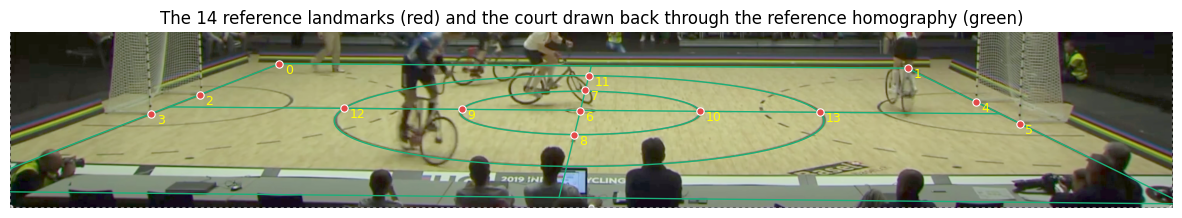

,landmark,x_m,y_m,x_px,y_px
0,far_left_corner,0.0,0.00,700.5,702.3
1,far_right_corner,14.0,0.00,2335.8,714.3
2,left_goal_far_post,0.0,4.25,493.8,783.7
3,left_goal_near_post,0.0,6.18,366.9,833.7
4,right_goal_far_post,14.0,4.32,2511.9,801.6
5,right_goal_near_post,14.0,6.37,2626.6,858.4
6,centre_spot,7.0,5.50,1482.8,825.0
7,inner_circle_far,7.0,3.50,1496.5,771.9
8,inner_circle_near,7.0,7.50,1467.2,889.0
9,inner_circle_left,5.0,5.50,1175.2,821.0


In [2]:
cap = cv2.VideoCapture(str(SAMPLE_CLIP))
ok, frame1 = cap.read()
cap.release()

fig, ax = plt.subplots(figsize=(15, 4.6))
ax.imshow(cv2.cvtColor(brighten(frame1), cv2.COLOR_BGR2RGB))
for line in court_lines():
    p = to_px(H_REF, line)
    ax.plot(p[:, 0], p[:, 1], color="#1baf7a", lw=1)
ax.scatter(REF_PX[:, 0], REF_PX[:, 1], s=28, c="#e34948", edgecolors="white", linewidths=0.8, zorder=3)
for i, (x, y) in enumerate(REF_PX):
    ax.annotate(str(i), (x, y), xytext=(4, -7), textcoords="offset points", color="yellow", fontsize=9)
ax.set_xlim(0, 3024); ax.set_ylim(1078, 620); ax.axis("off")
ax.set_title("The 14 reference landmarks (red) and the court drawn back through the reference homography (green)")
plt.show()

pd.DataFrame({"landmark": NAMES, "x_m": TEMPLATE_M[:, 0], "y_m": TEMPLATE_M[:, 1],
              "x_px": REF_PX[:, 0].round(1), "y_px": REF_PX[:, 1].round(1)})

## 4. Reference labels: measured once, checked twice

The camera is static, so the 14 labels only have to be found once. `tools/measure_court_keypoints.py` does it on a **background plate**: the median of 90 frames spread over the clip. A rider never stays in one place, so the median removes all riders and every marking is visible.

Instead of one click per landmark (the MVP way), each landmark is **measured from the markings around it**:
- end lines: about 60 points across the 6 px wide black line, the darkness-weighted middle of each, then a straight-line fit;
- far board: the dark-to-light step at its bottom edge, then a line fit; corner = where the two lines cross;
- goal post: the middle of the white post in every row, a line fit, crossed with the end line;
- circles: start where a first homography puts the point, then move across the painted line onto its darkest middle.

The tool also saves `outputs/keypoints/reference_check.jpg`, one zoomed crop per landmark, to check every label by eye.

**Check 1: the lines are straight to a fraction of a pixel.** A residual of several pixels would mean bent lines (lens distortion) or a bad fit.

**Check 2: the painted circles come out round.** One homography is fitted to the corners, the centre spot, ~340 points on the two painted circles and the goal posts. If the labels or the homography were wrong, the circles would come out as ellipses on the top-down court. The circle points are not keypoints, so this is an independent check.

In [3]:
checks = REF["checks"]
print(f"line fit residual (px): left end line {checks['left_end_line_rms_px']:.2f}, right end line "
      f"{checks['right_end_line_rms_px']:.2f}, far board edge {checks['far_board_edge_rms_px']:.2f}")
for ring in ("inner", "outer"):
    mean, std = checks[f"{ring}_circle_radius_m"]
    print(f"{ring} circle: radius {mean:.3f} m, spread around the circle {std * 100:.1f} cm")
label_err = pd.Series(checks["label_reprojection_error_m"]).mul(100).round(1)
print(f"\nlabel -> court error after fitting H to the 14 labels: mean {label_err.mean():.1f} cm, max {label_err.max():.1f} cm "
      f"({label_err.idxmax()})")

line fit residual (px): left end line 0.25, right end line 0.29, far board edge 0.89
inner circle: radius 1.975 m, spread around the circle 2.4 cm
outer circle: radius 3.960 m, spread around the circle 7.8 cm

label -> court error after fitting H to the 14 labels: mean 3.0 cm, max 9.8 cm (inner_circle_far)


**How good was the MVP's hand-clicked homography?** Now that we have a reference, we can measure it: where does the clicked homography put our 14 landmarks?

In [4]:
manual_err = np.linalg.norm(to_m(H_MANUAL, REF_PX) - TEMPLATE_M, axis=1)
print(f"MVP (clicked) homography at the 14 landmarks: mean {manual_err.mean():.2f} m, max {manual_err.max():.2f} m "
      f"({NAMES[manual_err.argmax()]})")

clicked = json.loads((ROOT / "data" / "court_keypoints.json").read_text())
for name in ("far_left_corner", "far_right_corner", "centre_spot"):
    d = np.subtract(clicked[name], REF["keypoints"][name]["px"])
    print(f"clicked {name:17s} is {np.hypot(*d):4.1f} px from the measured point (dx {d[0]:+.1f}, dy {d[1]:+.1f})")
near = to_m(H_REF, [clicked["near_sideline_left"], clicked["near_sideline_right"]])
print(f"the clicked 'near sideline' points are at y = {near[0, 1]:.2f} and {near[1, 1]:.2f} m on the reference court, not 11 m")

MVP (clicked) homography at the 14 landmarks: mean 0.33 m, max 0.71 m (inner_circle_near)
clicked far_left_corner   is  4.3 px from the measured point (dx +3.4, dy +2.6)
clicked far_right_corner  is  8.5 px from the measured point (dx +5.3, dy +6.6)
clicked centre_spot       is  3.2 px from the measured point (dx +3.2, dy +0.3)
the clicked 'near sideline' points are at y = 9.72 and 9.86 m on the reference court, not 11 m


**Why the clicked homography is off by up to 0.7 m.** The two "near sideline" clicks land at y = 9.7-9.9 m, more than a metre short of the sideline (11 m). The near sideline itself is not visible: the floor is hidden behind the near board from about y = 9.5 m (the outer circle's near point at (7, 9.5) is already behind it). So the clicks were on the **top of the near board**, about 0.3 m above the floor. That breaks the planar assumption: the homography maps the floor plane only, and a point 0.3 m up projects onto the floor further from the camera. Fitting "this is y = 11 m" to those points stretches the near half of the map. The far right corner click is also 8 px too low, which in depth is about 0.3 m at the far side (a far-side pixel covers ~4 cm of depth). Lesson for the labels: **only points on the floor, and measure rather than click.**

## 5. The dataset: one court, many virtual cameras

`data/prepare_keypoint_dataset.py`, settings in `configs/keypoints.yaml`:
- **Frames:** every 10th frame (about half the frames are copies of the previous one, neighbours barely differ).
- **Split by time,** the same as the detector: frames 1-234 are validation, the rest training. Riders in validation frames are at moments the model never saw.
- **Labels:** the 14 reference points are valid in every frame. Two label layouts for the same images: *court* (K0, K1: one `court` object whose box is the part of the court floor in the picture, with 14 keypoints) and *landmarks* (K2, section 10).
- **Visibility:** 2 = in the picture; 1 = in the picture but inside a rider or bike box from the detector (`models/detections.csv`); 0 = outside the picture. YOLO trains on 1 and 2 alike, so the model learns where a covered landmark is from the rest of the court. We keep the flag to check later whether covered landmarks are harder (section 12).
- **Virtual camera:** each frame is saved as filmed (`v0`) and as 3 (train) or 2 (val) views of a virtual camera: pan +-10 deg, tilt +-4 deg, roll +-3 deg, zoom 0.85-1.8 (1.8 shows about half the court; below 1 leaves black borders). A view with fewer than 4 landmarks in the picture is drawn again. Validation views use a different random seed, so they are camera positions the model never saw.

**Why these warps are realistic.** A camera that rotates around its own centre (pan, tilt, roll) and zooms sees *every* point, on the floor or not, through one homography: `x_new = K' R K^-1 x`, with `K` the camera's focal length (2900 px, a rough estimate from the court homography) and image centre, `R` the rotation and `K'` the zoomed focal length. So the virtual views are what a pan-tilt-zoom camera at the same spot would film, with riders and goals in the right place. A camera that also *moves* would show parallax, which a homography cannot fake; that is a limit of this augmentation.

In [5]:
# Build data/court-keypoints-dataset/ and data/court-landmarks-dataset/ (see the docstring at the top of the script).
%run ../data/prepare_keypoint_dataset.py

Wrote D:\Documents\Uni - Year 3\Deep Learning\computer-vision\data\court-keypoints-dataset and D:\Documents\Uni - Year 3\Deep Learning\computer-vision\data\court-landmarks-dataset
  val: 24 frames, 72 images (24 as filmed), visible keypoints per image: median 13, min 4
  train: 93 frames, 372 images (93 as filmed), visible keypoints per image: median 13, min 4


In [6]:
views = pd.read_csv(DATA / "views.csv")
views["kind"] = np.where(views.view == 0, "as filmed", "virtual camera")
val = views[views.split == "val"]
summary = (views.groupby(["split", "kind"], sort=False)
           .agg(images=("image", "size"), frames=("frame", "nunique"),
                landmarks_in_picture_median=("n_visible", "median"), landmarks_in_picture_min=("n_visible", "min")))
hidden = views.hidden.fillna("").str.split(";").map(lambda h: len([x for x in h if x]))
print(f"landmarks in the picture that sit inside a rider/bike box: {hidden.sum() / views.n_visible.sum():.0%}")
summary

landmarks in the picture that sit inside a rider/bike box: 20%


images  frames  landmarks_in_picture_median  \
split kind                                                          
val   as filmed           24      24                         14.0   
      virtual camera      48      24                         12.0   
train as filmed           93      93                         14.0   
      virtual camera     279      93                         12.0   

                      landmarks_in_picture_min  
split kind                                      
val   as filmed                             14  
      virtual camera                         4  
train as filmed                             14  
      virtual camera                         4

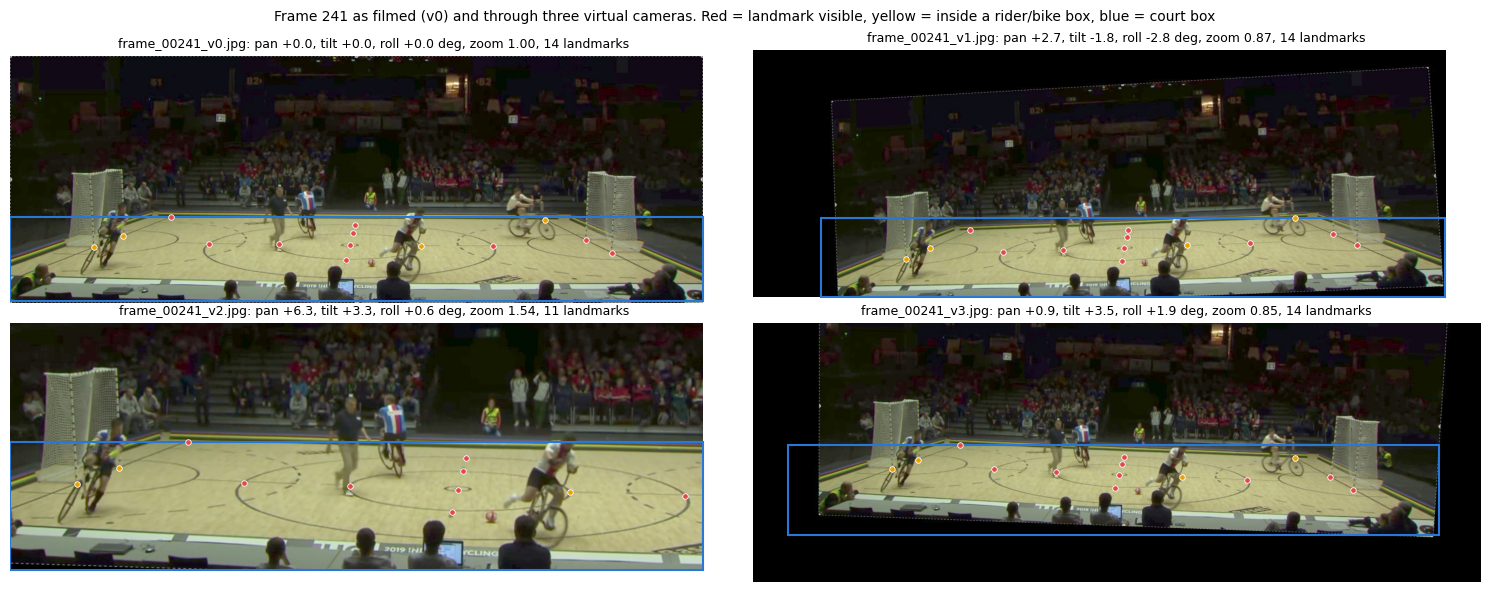

In [7]:
def draw_label(ax, split, image_name, title):
    image = cv2.imread(str(DATA / "images" / split / image_name))
    h, w = image.shape[:2]
    values = np.array((DATA / "labels" / split / image_name.replace(".jpg", ".txt")).read_text().split(), float)
    cx, cy, bw, bh = values[1:5]
    kpts = values[5:].reshape(-1, 3)
    ax.imshow(cv2.cvtColor(brighten(image), cv2.COLOR_BGR2RGB))
    ax.add_patch(plt.Rectangle(((cx - bw / 2) * w, (cy - bh / 2) * h), bw * w, bh * h, fill=False, ec="#2a78d6", lw=1.5))
    for vis, color in [(2, "#e34948"), (1, "#eda100")]:
        k = kpts[kpts[:, 2] == vis]
        ax.scatter(k[:, 0] * w, k[:, 1] * h, s=16, c=color, edgecolors="white", linewidths=0.6, zorder=3)
    ax.set_title(title, fontsize=9); ax.axis("off")

samples = views[(views.split == "train") & (views.frame == 241)]
fig, axes = plt.subplots(2, 2, figsize=(15, 6))
for ax, row in zip(axes.ravel(), samples.itertuples()):
    draw_label(ax, "train", row.image, f"{row.image}: pan {row.pan:+.1f}, tilt {row.tilt:+.1f}, roll {row.roll:+.1f} deg, "
               f"zoom {row.zoom:.2f}, {row.n_visible} landmarks")
fig.suptitle("Frame 241 as filmed (v0) and through three virtual cameras. Red = landmark visible, "
             "yellow = inside a rider/bike box, blue = court box", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Training K0 and K1

YOLO26n-pose from COCO pose weights, 50 epochs, AdamW (chosen by Ultralytics' `optimizer=auto`). Settings that differ from the defaults, and why:
- **imgsz 640.** Our laptop has no GPU: one training step takes 0.4 s per image at 640, 1.0 s at 960 and 2.1 s at 1280 (measured).
- **mosaic 0.** Mosaic glues 4 images together and crops the result, which cuts the court into pieces; our virtual views already move and zoom it. Flip (with `flip_idx`: left and right landmarks swap), HSV colour, translate and scale stay at the defaults.
- **batch 8, images read from disk, no dataloader workers.** On our 16 GB laptop, batch 16 with all images cached in RAM ran out of memory. Ultralytics accumulates gradients up to a nominal batch of 64 either way, so the effective batch size is the same.
- **Early stopping (patience 15)** for K0 and K1, the Ultralytics default mechanism. Section 8 shows this was a poor choice for us, so K2 trains the full 50 epochs.

**What the losses mean** (columns in `results.csv`, from `PoseLoss26` in the Ultralytics source):
- `box_loss` and `l1_loss`: the box (IoU loss plus an L1 loss on the box edges; YOLO26 has no DFL). `cls_loss`: the class.
- `pose_loss`: keypoint position, as 1 - OKS. OKS scales the error by the object's size (`d^2 / area`), so it is very forgiving for an object as large as the whole court.
- `kobj_loss`: binary cross-entropy on "is this landmark labelled" (visibility).
- `rle_loss`: *residual log-likelihood estimation*. The model also predicts how unsure it is about each keypoint (a sigma), and the loss is the negative log-likelihood of the true position under that uncertainty. Unlike the OKS term it keeps pushing small errors down.

**Helper** (as in notebook 07): `train(name, data)` trains into `runs/keypoints/<name>`. A finished run is skipped, so re-running the notebook only re-reads the results. A run that was cut off is resumed from `last.pt`: Ultralytics marks a finished checkpoint with `epoch = -1`.

In [8]:
SETTINGS = dict(imgsz=640, epochs=50, batch=8, patience=15, mosaic=0.0, seed=0, deterministic=True, cache=False,
                workers=0, device=DEVICE, plots=True)


def train(name, data, model=MODEL, **overrides):
    """Train into RUNS/name and return its last.pt. A finished run is skipped, a run that was cut off is resumed."""
    last = RUNS / name / "weights/last.pt"
    if not last.exists():
        YOLO(model).train(data=str(data), project=str(RUNS), name=name, exist_ok=True, **SETTINGS | overrides)
    elif torch.load(last, map_location="cpu", weights_only=False)["epoch"] != -1:   # Ultralytics sets epoch to -1 when a run finishes
        YOLO(last).train(resume=True, batch=SETTINGS["batch"], cache=False, workers=SETTINGS["workers"])
    return last

**K1: with the virtual camera** (372 training images: 93 frames as filmed + 3 virtual views each).

In [9]:
last_k1 = train("k1_virtual_camera", DATA / "data.yaml")

**K0: frames as filmed only** (93 training images), same settings and the same validation set.

In [10]:
last_k0 = train("k0_as_filmed", DATA / "data_as_filmed.yaml")

**Run history (13 Nov).** K1 was stopped twice by the laptop running out of memory (at epochs 16 and 30) and resumed from `last.pt` each time. Its first 16 epochs ran with batch 16 and the images cached in RAM; from epoch 17 on with batch 8 from disk (the settings above). The effective batch is 64 in both cases. K1 then stopped early at epoch 37: Ultralytics' fitness (section 8) peaked at epoch 22 and did not improve for 15 epochs. K0 ran all 50 epochs with the settings above. K0 and K1 were finished from a terminal with these same settings (to avoid the memory stops), so their training cells above show no output: they find the finished runs and skip them. K2 was trained by running this notebook.

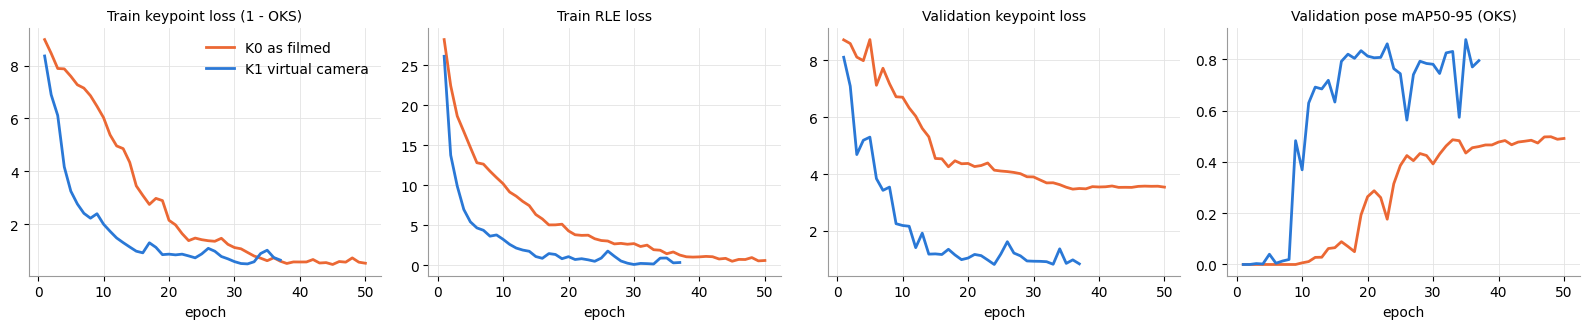

In [33]:
def load_results(run):
    return pd.read_csv(run / "results.csv").rename(columns=str.strip)

panels = [("train/pose_loss", "Train keypoint loss (1 - OKS)"), ("train/rle_loss", "Train RLE loss"),
          ("val/pose_loss", "Validation keypoint loss"), ("metrics/mAP50-95(P)", "Validation pose mAP50-95 (OKS)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (column, title) in zip(axes, panels):
    for name in ["K0 as filmed", "K1 virtual camera"]:
        r = load_results(RUN_DIRS[name])
        ax.plot(r.epoch, r[column], color=COLORS[name], label=name)
    ax.set_title(title, fontsize=10); ax.set_xlabel("epoch")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

All loss curves of K1, as Ultralytics plots them (top: training, bottom: validation and metrics):

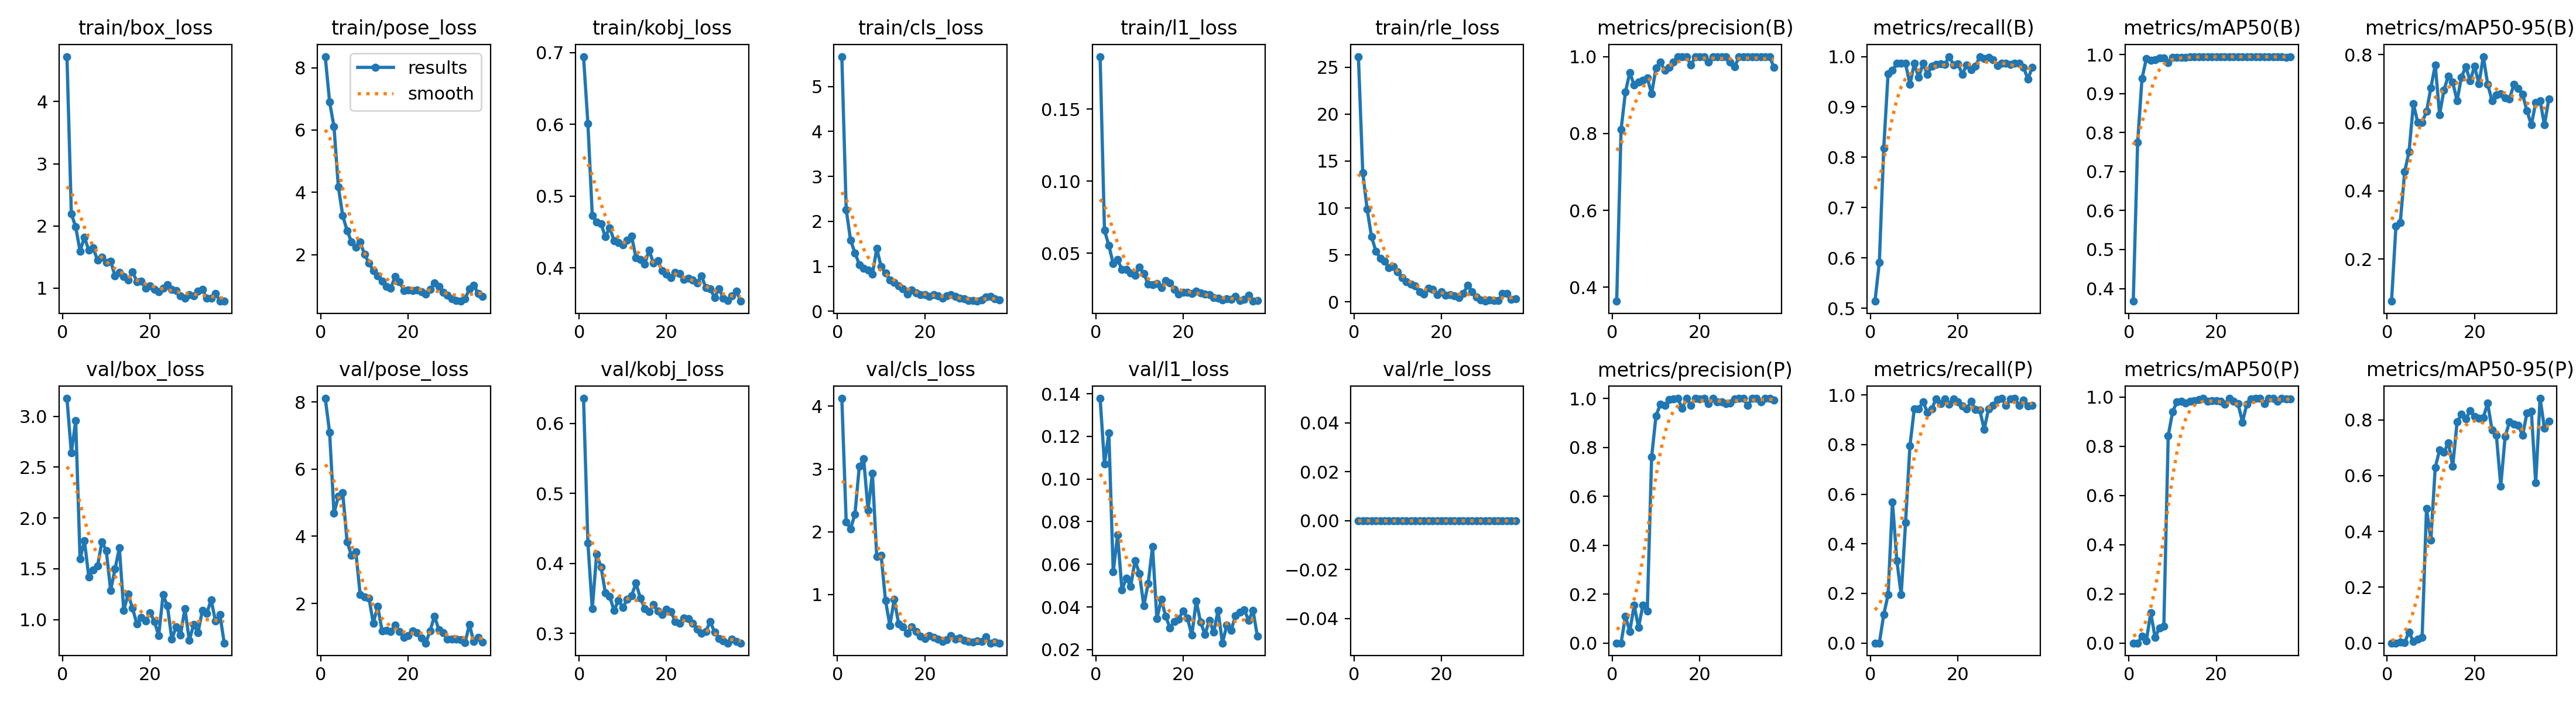

In [12]:
display(Image(filename=str(RUN_DIRS["K1 virtual camera"] / "results.png"), width=1000))

K0's training loss ends *lower* than K1's, but its validation loss stays about 4 times higher. K0 learns its 93 training images by heart (always the same camera) and that does not carry over to new views: the memorisation from section 2, visible in the losses. K1's validation loss is still falling when early stopping ends it at epoch 37 (section 8). The pose mAP curve jumps by up to 0.3 from one epoch to the next on 72 validation images, so a single epoch's mAP is a noisy number.

## 7. The standard metric: pose mAP (OKS)

Ultralytics validation on the whole val set, and on its two halves: frames as filmed and virtual-camera views. Pose mAP counts a court as found when its OKS (object keypoint similarity) is above a threshold, 0.50 to 0.95.

In [13]:
def val_subset(name, images):
    """data.yaml copy whose val set is only these images (a txt list), for Ultralytics val."""
    (DATA / f"val_{name}.txt").write_text("\n".join(f"./images/val/{i}" for i in images) + "\n")
    data = yaml.safe_load((DATA / "data.yaml").read_text())
    path = DATA / f"data_val_{name}.yaml"
    path.write_text(yaml.safe_dump({**data, "val": f"val_{name}.txt"}, sort_keys=False))
    return path

subsets = {"all val": DATA / "data.yaml",
           "as filmed": val_subset("as_filmed", val[val.view == 0].image),
           "virtual camera": val_subset("virtual", val[val.view > 0].image)}
rows = []
for model_name in ["K0 as filmed", "K1 virtual camera"]:
    run = RUN_DIRS[model_name]
    model = YOLO(run / "weights" / "last.pt")
    for subset, data in subsets.items():
        m = model.val(data=str(data), imgsz=640, batch=8, plots=False, verbose=False, device=DEVICE,
                      project=str(RUNS / "val"), name=f"{run.name}_{subset.replace(' ', '_')}", exist_ok=True)
        rows.append({"model": model_name, "val images": subset, "box mAP50": m.box.map50, "pose mAP50": m.pose.map50,
                     "pose mAP50-95": m.pose.map})
pd.DataFrame(rows).round(3)

,model,val images,box mAP50,pose mAP50,pose mAP50-95
0,K0 as filmed,all val,0.843,0.655,0.490
1,K0 as filmed,as filmed,0.995,0.995,0.884
2,K0 as filmed,virtual camera,0.768,0.475,0.324
3,K1 virtual camera,all val,0.994,0.994,0.794
4,K1 virtual camera,as filmed,0.995,0.995,0.866
5,K1 virtual camera,virtual camera,0.992,0.991,0.758


 On the frames as filmed, K0 has the *higher* pose mAP50-95 (0.884 vs 0.866): the memorised model looks best. On the virtual-camera views it collapses (0.324 vs 0.758). In metres (section 8) K0 is worse than K1 on both halves, so on the frames as filmed pose mAP ranks the two models the wrong way round.

**Why we don't stop at mAP.** OKS divides the squared pixel error by the object's area. Our object is the whole court (about 640 x 220 px at the model's input size), so even a 20 px error, which is ~95 px in the 3024 px frame and more than a metre in depth at the far side, still gives OKS ~ 0.93. Pose mAP says "the court was found and the landmarks are roughly right", not "precise enough for a homography". What matters for the minimap is the **error in metres on the court**.

## 8. Error in metres

For every validation image we know the exact image-to-court homography `G`: the reference homography combined with that view's virtual-camera warp (saved per image in `views.csv`). So we measure:
- **landmark error (m):** put the predicted pixel through `G` and measure its distance to where that landmark is on the court;
- **homography error (m):** fit `H` from the predicted landmarks the way the app does (confidence >= 0.5, RANSAC with a 0.3 m threshold), map a 0.5 m grid of court points that are in the picture through `H`, and take the mean distance to where they should be. This is what a rider's dot on the minimap would be off by.

In [14]:
def ground_truth(row):
    """Label pixels (14, 2, as 0-1 fractions), visibility (14,) and the image -> court homography G of one image."""
    values = np.array((DATA / "labels" / row.split / row.image.replace(".jpg", ".txt")).read_text().split(), float)
    kpts = values[5:].reshape(-1, 3)
    G = np.array([getattr(row, f"g{i}") for i in range(9)]).reshape(3, 3)
    return kpts[:, :2], kpts[:, 2], G

GRID = np.stack(np.meshgrid(np.arange(0, 14.01, 0.5), np.arange(0, 11.01, 0.5)), -1).reshape(-1, 2)

def grid_error(H, G, size):
    """Mean and max distance (m) between where H and the true G put the court grid points in the picture,
    and the mean over the near zone (y > 7.5 m, beyond the last landmark)."""
    px = to_px(G, GRID)
    inside = (px[:, 0] >= 0) & (px[:, 0] < size[0]) & (px[:, 1] >= 0) & (px[:, 1] < size[1])
    err = np.linalg.norm(to_m(H, px[inside]) - GRID[inside], axis=1)
    near = GRID[inside, 1] > 7.5
    return err.mean(), err.max(), err[near].mean() if near.any() else np.nan

def evaluate(model_path, rows=val):
    """One row per (image, landmark) and one row per image."""
    model = YOLO(model_path)
    per_kpt, per_image = [], []
    for row in rows.itertuples():
        image = cv2.imread(str(DATA / "images" / row.split / row.image))
        size = image.shape[1], image.shape[0]
        xy, conf = keypoints_in_frame(model, image)
        gt, vis, G = ground_truth(row)
        hidden_names = set(str(row.hidden).split(";"))
        err_m = np.linalg.norm(to_m(G, xy) - TEMPLATE_M, axis=1)
        for k, name in enumerate(NAMES):
            per_kpt.append({"image": row.image, "kind": row.kind, "landmark": name, "in_picture": vis[k] > 0,
                            "hidden": name in hidden_names, "found": conf[k] >= MIN_CONFIDENCE, "error_m": err_m[k]})
        H, inliers = homography_from_keypoints(xy, conf)
        mean, worst, near = grid_error(H, G, size) if H is not None else (np.nan, np.nan, np.nan)
        per_image.append({"image": row.image, "kind": row.kind, "zoom": row.zoom, "pan": row.pan,
                          "in_picture": int((vis > 0).sum()), "found": int((conf >= MIN_CONFIDENCE).sum()),
                          "used": int(inliers.sum()), "has_H": H is not None, "grid_mean_m": mean, "grid_max_m": worst,
                          "grid_near_m": near})
    return pd.DataFrame(per_kpt), pd.DataFrame(per_image)

def summarise(label, kpt, img):
    """One table row per kind of val image."""
    out = []
    for kind in ["as filmed", "virtual camera"]:
        kk, ii = kpt[(kpt.kind == kind) & kpt.in_picture], img[img.kind == kind]
        out.append({"model": label, "val images": kind, "landmarks found": kk.found.mean(),
                    "landmark error median (m)": kk[kk.found].error_m.median(),
                    "views without H": int((~ii.has_H).sum()),
                    "H error mean (m)": ii.grid_mean_m.mean(), "H error median (m)": ii.grid_mean_m.median(),
                    "H error worst view (m)": ii.grid_mean_m.max()})
    return out

kpt_eval, img_eval, table = {}, {}, []
for name in ["K0 as filmed", "K1 virtual camera"]:
    kpt_eval[name], img_eval[name] = evaluate(RUN_DIRS[name] / "weights" / "last.pt")
    table += summarise(name, kpt_eval[name], img_eval[name])
pd.DataFrame(table).round(3)

,model,val images,landmarks found,landmark error median (m),views without H,H error mean (m),H error median (m),H error worst view (m)
0,K0 as filmed,as filmed,1.000,0.579,0,0.638,0.639,0.866
1,K0 as filmed,virtual camera,0.687,0.867,17,48.015,1.001,1447.809
2,K1 virtual camera,as filmed,1.000,0.378,0,0.550,0.550,0.644
3,K1 virtual camera,virtual camera,0.976,0.462,0,0.759,0.652,2.767


**Which checkpoint?** Ultralytics saves `best.pt` at the epoch with the best *fitness*, which for pose models is box mAP50-95 + pose mAP50-95 (`PoseMetrics.fitness`). Neither measures metres. The same fitness drives early stopping. Here are both checkpoints of each run, in metres:

In [15]:
ckpt_rows = []
for name in ["K0 as filmed", "K1 virtual camera"]:
    log = load_results(RUN_DIRS[name])
    fitness = log["metrics/mAP50-95(B)"] + log["metrics/mAP50-95(P)"]
    for weights, epoch in [("best.pt", int(log.epoch[fitness.idxmax()])), ("last.pt", int(log.epoch.iloc[-1]))]:
        k, i = (kpt_eval[name], img_eval[name]) if weights == "last.pt" else evaluate(RUN_DIRS[name] / "weights" / weights)
        for r in summarise(f"{name} {weights} (epoch {epoch})", k, i):
            ckpt_rows.append({key: r[key] for key in ["model", "val images", "H error mean (m)", "H error median (m)",
                                                      "views without H"]})
pd.DataFrame(ckpt_rows).round(3)

,model,val images,H error mean (m),H error median (m),views without H
0,K0 as filmed best.pt (epoch 47),as filmed,0.663,0.622,0
1,K0 as filmed best.pt (epoch 47),virtual camera,1.465,0.965,17
2,K0 as filmed last.pt (epoch 50),as filmed,0.638,0.639,0
3,K0 as filmed last.pt (epoch 50),virtual camera,48.015,1.001,17
4,K1 virtual camera best.pt (epoch 22),as filmed,0.518,0.534,0
5,K1 virtual camera best.pt (epoch 22),virtual camera,0.897,0.826,0
6,K1 virtual camera last.pt (epoch 37),as filmed,0.550,0.550,0
7,K1 virtual camera last.pt (epoch 37),virtual camera,0.759,0.652,0


For K1, `best.pt` (epoch 22) is slightly better on the frames as filmed (0.52 vs 0.55 m) and clearly worse on the virtual views (0.90 vs 0.76 m mean). For K0 the two are close (17 views without H either way). So the fitness Ultralytics maximises does not pick the checkpoint that is best in metres, and it stopped K1 at epoch 37 while the validation keypoint loss was still falling. We use **`last.pt`** (the end of training) for every model from here on: it does not depend on a selection metric that ignores what we need, and it is not chosen on the validation set, so the validation numbers stay honest.

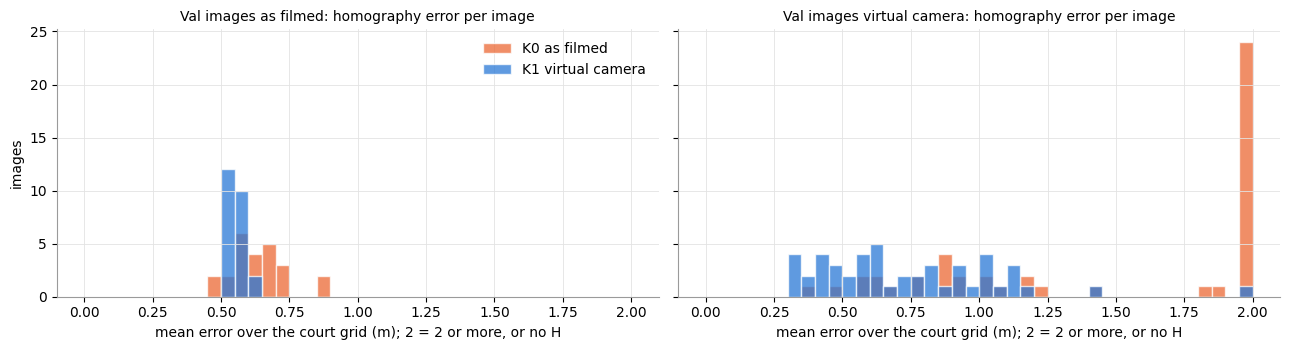

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
bins = np.linspace(0, 2, 41)
for ax, kind in zip(axes, ["as filmed", "virtual camera"]):
    for name in ["K0 as filmed", "K1 virtual camera"]:
        e = img_eval[name]
        e = e[e.kind == kind].grid_mean_m.fillna(2).clip(upper=2)
        ax.hist(e, bins=bins, color=COLORS[name], alpha=0.75, label=name, edgecolor="white", linewidth=1)
    ax.set_title(f"Val images {kind}: homography error per image", fontsize=10)
    ax.set_xlabel("mean error over the court grid (m); 2 = 2 or more, or no H")
axes[0].set_ylabel("images"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**K0 vs K1.** Both find every landmark on the frames as filmed, and K1 is a bit better there (0.55 vs 0.64 m). On the virtual-camera views K0 falls apart: it finds only 69% of the landmarks, 17 of 48 views give no homography at all, and in one view the homography is off by more than a kilometre. K0 has learned where the landmarks *were*, not what they look like. K1 finds 98% and gives a homography for every view. So the virtual camera did its job. But 0.55 m is no better than the clicked points, which is why the next section looks closer.

## 9. What went wrong with K1: the court is squeezed

K1 beats K0 on the virtual views, but on the frames as filmed it is no better than the clicked homography (0.52 m, section 11). To see why, split each prediction's error into a **constant part** (the same in every frame: a bias) and a **varying part** (noise). On the validation frames as filmed, the camera is the same in every frame, so the mean error per landmark is the bias.

In [17]:
def signed_errors(model_path):
    """Per (val frame as filmed, landmark): predicted minus reference position, in full-frame pixels."""
    model = YOLO(model_path)
    rows = []
    for row in val[val.view == 0].itertuples():
        image = cv2.imread(str(DATA / "images" / "val" / row.image))
        xy, conf = keypoints_in_frame(model, image)
        d = xy * (3024 / image.shape[1]) - REF_PX
        rows += [{"landmark": n, "dx": d[k, 0], "dy": d[k, 1], "found": conf[k] >= MIN_CONFIDENCE}
                 for k, n in enumerate(NAMES)]
    return pd.DataFrame(rows)

errors = {"K1 virtual camera": signed_errors(RUN_DIRS["K1 virtual camera"] / "weights" / "last.pt")}
e = errors["K1 virtual camera"]
g = e[e.found].groupby("landmark", sort=False)
pd.DataFrame({"bias dx (px)": g.dx.mean(), "bias dy (px)": g.dy.mean(), "noise dx (px, sd)": g.dx.std(),
              "noise dy (px, sd)": g.dy.std()}).reindex(NAMES).round(1)

,bias dx (px),bias dy (px),"noise dx (px, sd)","noise dy (px, sd)"
landmark,,,,
far_left_corner,33.2,12.6,9.7,2.4
far_right_corner,-83.8,-6.7,6.1,2.3
left_goal_far_post,75.5,14.5,10.9,2.9
left_goal_near_post,95.2,14.6,11.3,2.6
right_goal_far_post,-96.6,-15.6,6.9,2.5
right_goal_near_post,-101.2,-25.9,7.5,2.7
centre_spot,14.9,-4.6,5.9,2.6
inner_circle_far,-1.4,-0.1,6.0,2.5
inner_circle_near,28.6,-5.9,5.9,3.1


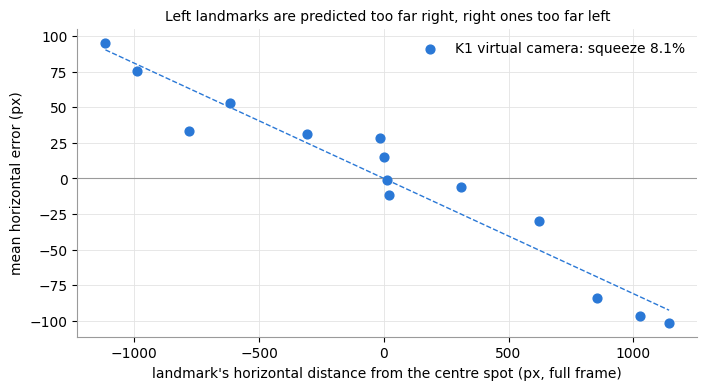

In [18]:
CENTRE_X = REF["keypoints"]["centre_spot"]["px"][0]

def squeeze_plot(ax, label):
    """Bias in x against the landmark's distance from the centre spot. A straight line through 0 = a uniform squeeze."""
    e = errors[label]
    bias = e[e.found].groupby("landmark").dx.mean().reindex(NAMES).to_numpy()
    dist = REF_PX[:, 0] - CENTRE_X
    ok = ~np.isnan(bias)
    slope = (dist[ok] * bias[ok]).sum() / (dist[ok] ** 2).sum()           # least squares through the origin
    ax.scatter(dist, bias, s=40, color=COLORS[label], label=f"{label}: squeeze {-slope:.1%}", zorder=3)
    xs = np.array([dist.min(), dist.max()])
    ax.plot(xs, slope * xs, color=COLORS[label], lw=1, ls="--")
    return slope

fig, ax = plt.subplots(figsize=(8, 4))
squeeze_plot(ax, "K1 virtual camera")
ax.axhline(0, color="#9a9a9a", lw=0.8)
ax.set_xlabel("landmark's horizontal distance from the centre spot (px, full frame)")
ax.set_ylabel("mean horizontal error (px)"); ax.legend(frameon=False)
ax.set_title("Left landmarks are predicted too far right, right ones too far left", fontsize=10)
plt.show()

 The errors are almost all bias: per landmark the noise between frames is a few pixels, the bias up to ~100 px. And the bias is *proportional to the distance from the centre*: the predicted court is a uniformly squeezed copy of the real one. Averaging over more frames cannot fix that.

**Root cause (hypothesis, from the Ultralytics source).** YOLO26's pose head predicts each keypoint as an offset from the grid cell (anchor) that detects the object: `keypoint = (prediction + anchor) * stride` (`Pose26.kpts_decode`). Our object is the whole court, so its anchors sit near the middle and the corners and goal posts are hundreds of pixels away: offsets of ~10 strides. Regressing long offsets from one place is hard, and a network that is unsure shrinks them towards zero, i.e. towards the anchor. The OKS loss does little against it, because it divides the error by the court's huge area (section 7). Human pose does not have this problem: joints are close to the person's centre.

**Prediction that tests the hypothesis.** If the long offsets are the problem, then making every landmark its own small object (its anchor right on top of it) should remove the squeeze. That is K2.

## 10. K2: every landmark its own object

Same images, same settings, one change in the labels (`data/court-landmarks-dataset`, written by the same script): **14 classes, one per landmark**, each with a small box (120 px on the full frame, ~25 px at the model's input) around the landmark and **1 keypoint**, the landmark itself. The keypoint is now at most half a box from its anchor. Two settings follow from that:
- **No left-right flips** (`fliplr=0`): a mirrored left corner looks like a right corner but would keep the class "far left corner". With 14 classes, the class *is* the landmark's identity.
- **No early stopping** (`patience=0`), for the reason in section 8: K2 trains the full 50 epochs and we use its `last.pt`.

At prediction time each class's most confident box gives that landmark (`keypoints_in_frame` in `app/core/court_keypoints.py` handles both layouts); its confidence is the box's.

In [19]:
last_k2 = train("k2_landmarks", LM_DATA / "data.yaml", fliplr=0.0, patience=0)

**K2's training curves.** Training and validation losses fall together and flatten from about epoch 30 (validation keypoint loss 0.059 -> 0.013), with no sign of overfitting, so 50 epochs were enough. The values are not comparable with K1's: K2's losses are per landmark object, and OKS divides by each small box's area instead of the whole court's.

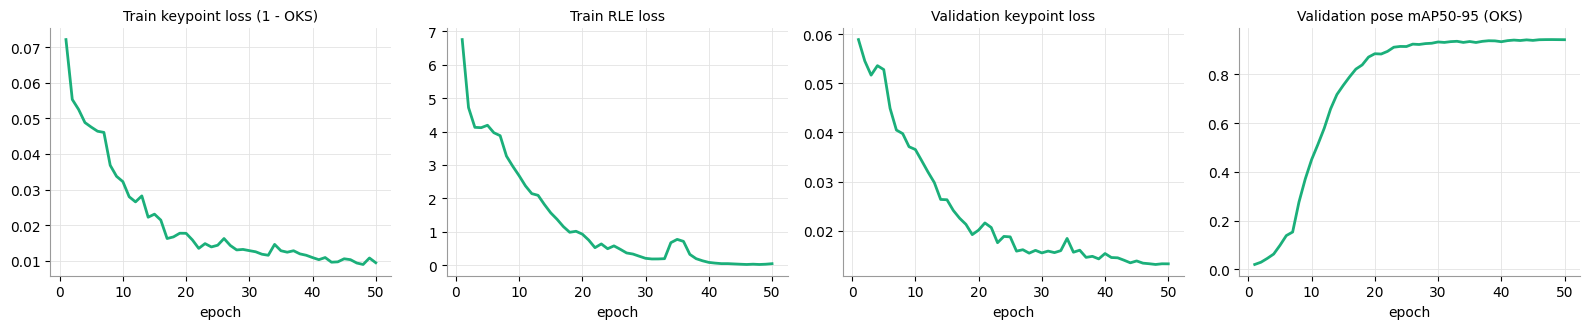

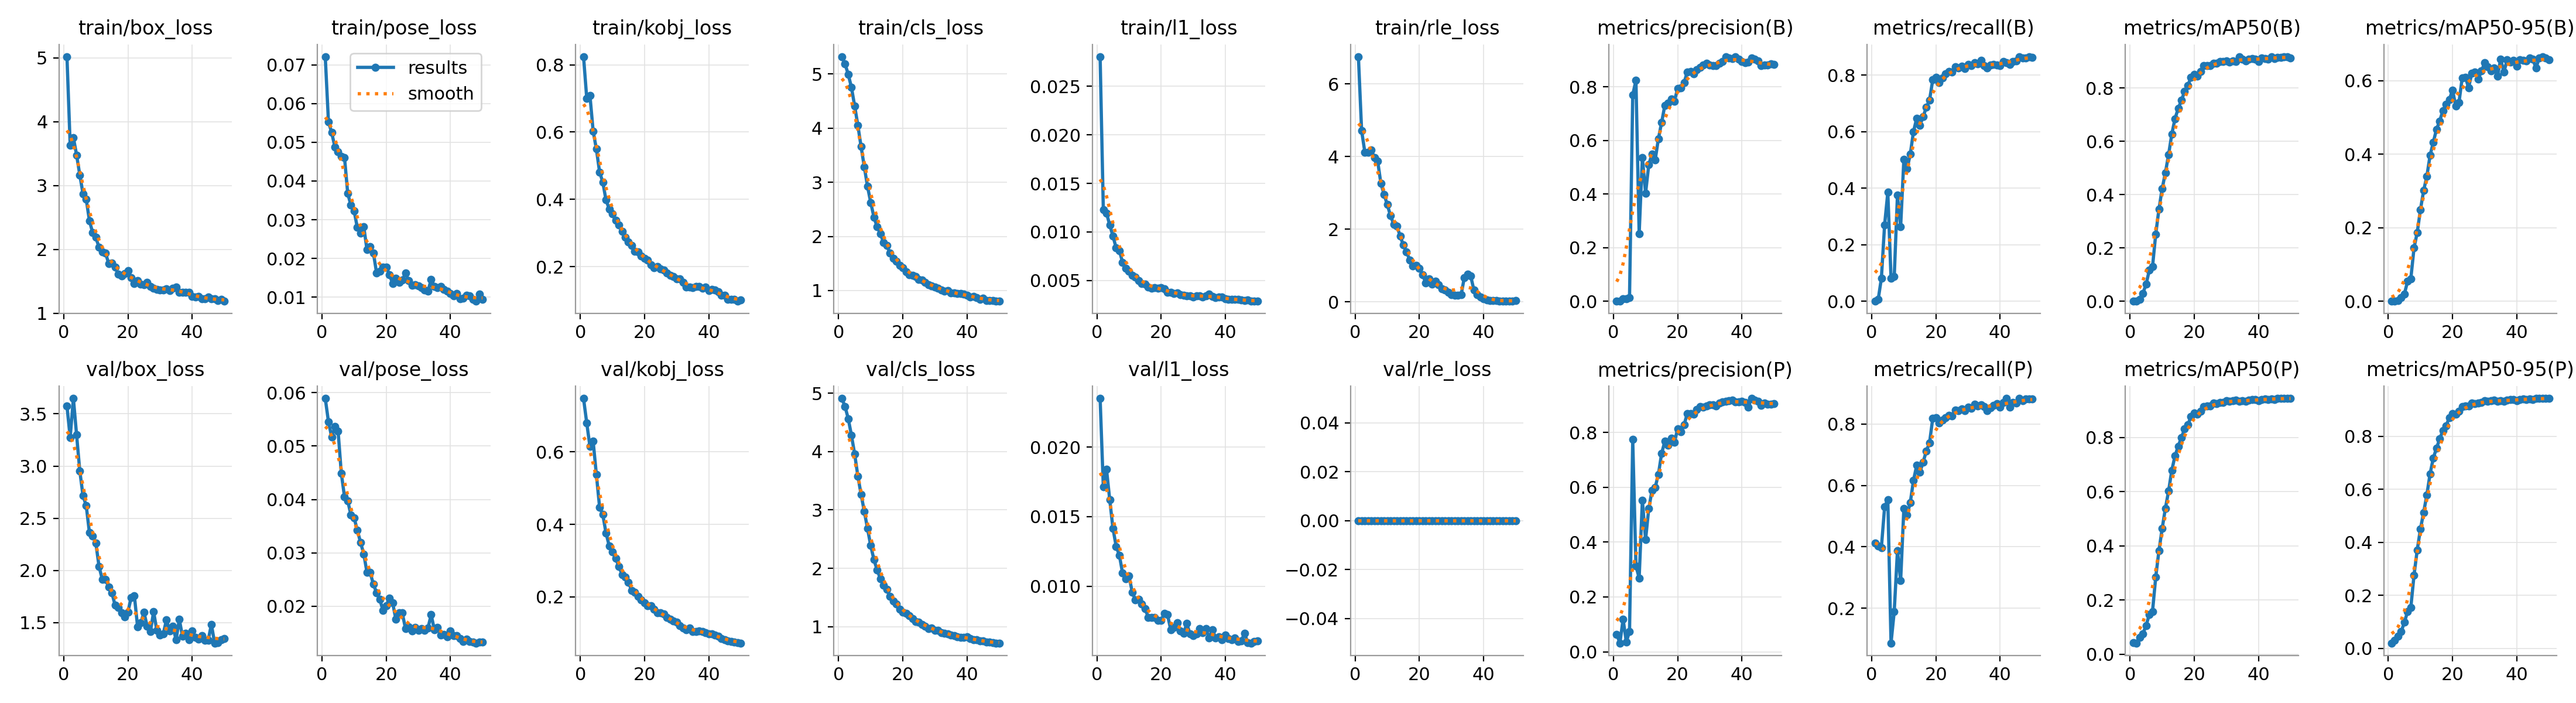

In [34]:
r = load_results(RUN_DIRS["K2 landmarks"])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (column, title) in zip(axes, [("train/pose_loss", "Train keypoint loss (1 - OKS)"), ("train/rle_loss", "Train RLE loss"),
                                      ("val/pose_loss", "Validation keypoint loss"), ("metrics/mAP50-95(P)", "Validation pose mAP50-95 (OKS)")]):
    ax.plot(r.epoch, r[column], color=COLORS["K2 landmarks"])
    ax.set_title(title, fontsize=10); ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()
display(Image(filename=str(RUN_DIRS["K2 landmarks"] / "results.png"), width=1000))

In [20]:
kpt_eval["K2 landmarks"], img_eval["K2 landmarks"] = evaluate(last_k2)
table += summarise("K2 landmarks", kpt_eval["K2 landmarks"], img_eval["K2 landmarks"])
pd.DataFrame(table).round(3)

,model,val images,landmarks found,landmark error median (m),views without H,H error mean (m),H error median (m),H error worst view (m)
0,K0 as filmed,as filmed,1.000,0.579,0,0.638,0.639,0.866
1,K0 as filmed,virtual camera,0.687,0.867,17,48.015,1.001,1447.809
2,K1 virtual camera,as filmed,1.000,0.378,0,0.550,0.550,0.644
3,K1 virtual camera,virtual camera,0.976,0.462,0,0.759,0.652,2.767
4,K2 landmarks,as filmed,0.938,0.093,0,0.124,0.101,0.398
5,K2 landmarks,virtual camera,0.839,0.109,1,0.738,0.136,21.293


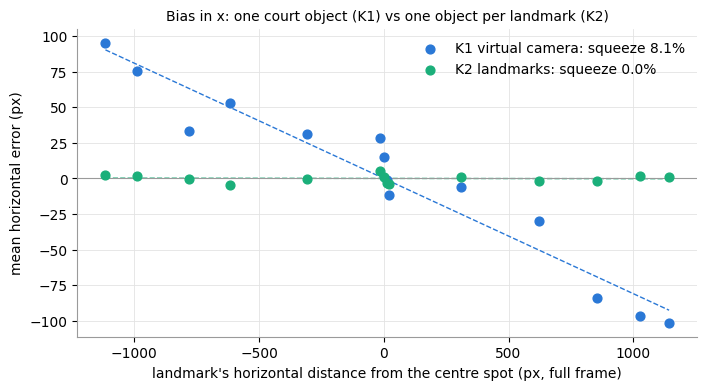

K1 virtual camera  bias (mean |per-landmark mean|): dx  47.3 px, dy  8.9 px | noise (median sd): dx  6.5 px, dy  2.6 px
K2 landmarks       bias (mean |per-landmark mean|): dx   2.1 px, dy  3.1 px | noise (median sd): dx  4.0 px, dy  3.1 px


In [21]:
errors["K2 landmarks"] = signed_errors(last_k2)
fig, ax = plt.subplots(figsize=(8, 4))
for label in ["K1 virtual camera", "K2 landmarks"]:
    squeeze_plot(ax, label)
ax.axhline(0, color="#9a9a9a", lw=0.8)
ax.set_xlabel("landmark's horizontal distance from the centre spot (px, full frame)")
ax.set_ylabel("mean horizontal error (px)"); ax.legend(frameon=False)
ax.set_title("Bias in x: one court object (K1) vs one object per landmark (K2)", fontsize=10)
plt.show()
for label in ["K1 virtual camera", "K2 landmarks"]:
    e = errors[label]
    e = e[e.found]
    print(f"{label:18s} bias (mean |per-landmark mean|): dx {e.groupby('landmark').dx.mean().abs().mean():5.1f} px, "
          f"dy {e.groupby('landmark').dy.mean().abs().mean():4.1f} px | noise (median sd): "
          f"dx {e.groupby('landmark').dx.std().median():4.1f} px, dy {e.groupby('landmark').dy.std().median():4.1f} px")

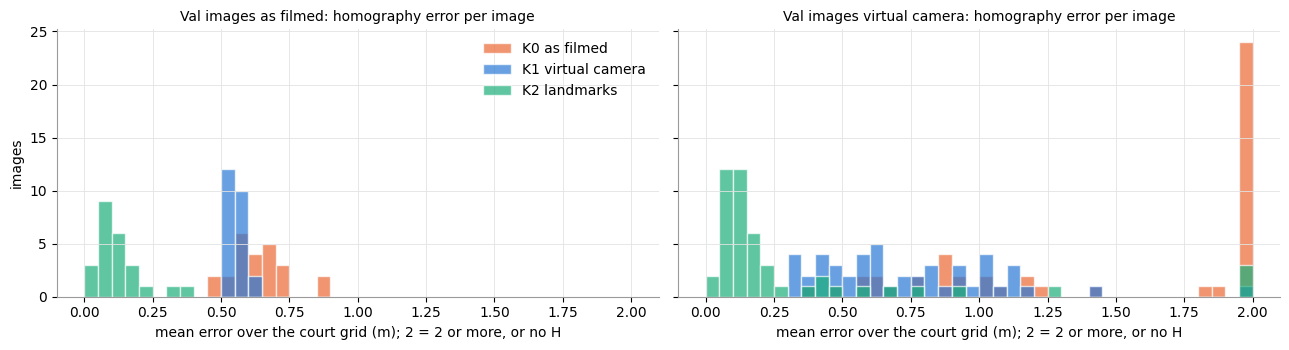

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, kind in zip(axes, ["as filmed", "virtual camera"]):
    for name in RUN_DIRS:
        e = img_eval[name]
        e = e[e.kind == kind].grid_mean_m.fillna(2).clip(upper=2)
        ax.hist(e, bins=bins, color=COLORS[name], alpha=0.7, label=name, edgecolor="white", linewidth=1)
    ax.set_title(f"Val images {kind}: homography error per image", fontsize=10)
    ax.set_xlabel("mean error over the court grid (m); 2 = 2 or more, or no H")
axes[0].set_ylabel("images"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**K2 vs K1.** The squeeze is gone. The mean bias per landmark drops from 47 to 2 px horizontally and from 9 to 3 px vertically, while the noise between frames stays small (K1: 6.5 and 2.6 px, K2: 4.0 and 3.1 px). That is what the hypothesis in section 9 predicted, so the long offsets from one anchor were the cause. In metres:
- frames as filmed: homography error 0.55 -> **0.12 m** (median 0.10 m), landmark error 0.38 -> 0.09 m;
- virtual-camera views: median 0.65 -> **0.14 m**, but the mean (0.74 m) is pulled up by a few views that fail badly (worst 21 m, one view without H; section 12.2).

**The price:** K2 finds fewer landmarks (94% as filmed, 84% in virtual views, against 100% and 98% for K1). K1 predicted every landmark from the whole court, also the ones a rider covers, but all of them squeezed. K2 looks at each landmark where it is, so a covered landmark is often simply not found. For a homography that is the better trade: a missing landmark costs some redundancy, a misplaced one pulls the whole fit.

## 11. Hand-off to the app: one homography for the clip

**Which model.** The one with the lowest mean homography error on the validation images (as filmed and virtual views together). This is the only choice made on the validation set (2 candidates), so the validation numbers above are slightly optimistic for the winner.

The sample clip's camera is static, so the app needs one `H`. `tools/auto_homography.py` runs the model on 30 frames spread over the clip. In each frame riders cover different landmarks, so per landmark it takes the **median position over the frames where it was found**, then fits `H` once (RANSAC). It saves `H` to `models/court_homography.json`, which `app/core/homography.py` uses when `HOMOGRAPHY_SOURCE = "keypoints"` (`app/core/config.py`). The chosen weights are copied to `models/court_keypoints.pt` (in git, like `models/best.pt`).

In [23]:
val_error = {name: img_eval[name].grid_mean_m.mean() for name in ["K1 virtual camera", "K2 landmarks"]}
FINAL = min(val_error, key=val_error.get)
print("mean homography error on val:", {k: round(v, 3) for k, v in val_error.items()}, "->", FINAL)
shutil.copy(RUN_DIRS[FINAL] / "weights" / "last.pt", ROOT / "models" / "court_keypoints.pt")
%run ../tools/auto_homography.py

mean homography error on val: {'K1 virtual camera': np.float64(0.689), 'K2 landmarks': np.float64(0.53)} -> K2 landmarks
13 of 14 landmarks used; error at the used ones: mean 0.079 m
wrote D:\Documents\Uni - Year 3\Deep Learning\computer-vision\models\court_homography.json


In [24]:
auto = json.loads((ROOT / "models" / "court_homography.json").read_text())
H_AUTO = np.array(auto["H_px_to_m"])
landmarks = pd.DataFrame(auto["landmarks"]).T
landmarks["error vs reference (px)"] = np.linalg.norm(np.stack(landmarks.px.to_numpy()) - REF_PX, axis=1).round(1)
landmarks.drop(columns="px").rename(columns={"frames_found": f"found in frames (of {auto['frames_sampled']})",
                                             "spread_px": "jitter between frames (px)", "error_m": "fit residual (m)"})

,found in frames (of 30),used,fit residual (m),jitter between frames (px),error vs reference (px)
far_left_corner,30,True,0.062,4.1,1.3
far_right_corner,30,True,0.065,3.2,2.3
left_goal_far_post,30,True,0.13,3.4,2.4
left_goal_near_post,30,True,0.036,1.5,0.7
right_goal_far_post,30,True,0.117,2.1,3.3
right_goal_near_post,30,True,0.033,1.1,1.7
centre_spot,29,True,0.165,3.4,7.2
inner_circle_far,27,False,0.431,4.2,7.1
inner_circle_near,30,True,0.207,1.7,3.1
inner_circle_left,30,True,0.04,1.7,1.8


**Clicked vs automatic,** both measured against the reference on a 0.25 m grid over the whole court. The app's `H` uses 30 frames from the whole clip, so 80% of them are frames the model trained on (as filmed): this is a deployment check. The held-out version below uses only validation frames (1-234).

K2 landmarks: H from 30 validation frames only (1-234): mean error 0.14 m


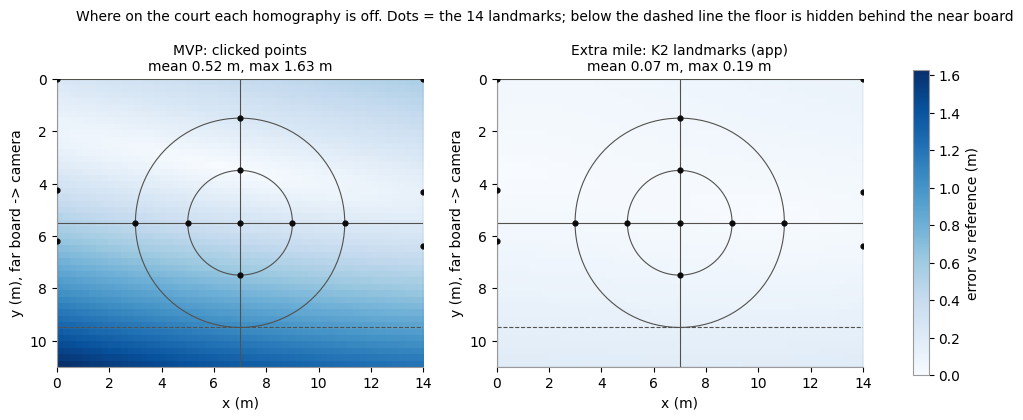

In [25]:
fine = np.stack(np.meshgrid(np.arange(0, 14.01, 0.25), np.arange(0, 11.01, 0.25)), -1)

def error_map(H):
    px = to_px(H_REF, fine.reshape(-1, 2))
    return np.linalg.norm(to_m(H, px) - fine.reshape(-1, 2), axis=1).reshape(fine.shape[:2])

FINAL_MODEL = YOLO(ROOT / "models" / "court_keypoints.pt")
H_HELD_OUT, _ = homography_from_video(SAMPLE_CLIP, 30, model=FINAL_MODEL, frame_range=(1, CFG["val_last_frame"]))
print(f"{FINAL}: H from 30 validation frames only (1-{CFG['val_last_frame']}): mean error {error_map(H_HELD_OUT).mean():.2f} m")

maps = {"MVP: clicked points": error_map(H_MANUAL), f"Extra mile: {FINAL} (app)": error_map(H_AUTO)}
vmax = max(m.max() for m in maps.values())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (title, m) in zip(axes, maps.items()):
    im = ax.imshow(m, extent=(0, 14, 11, 0), cmap="Blues", vmin=0, vmax=vmax)
    for line in court_lines():
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.8)
    ax.axhline(9.5, color="#52514e", ls="--", lw=0.8)
    ax.scatter(TEMPLATE_M[:, 0], TEMPLATE_M[:, 1], s=12, c="#0b0b0b", zorder=3)
    ax.set_title(f"{title}\nmean {m.mean():.2f} m, max {m.max():.2f} m", fontsize=10)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m), far board -> camera"); ax.grid(False)
fig.colorbar(im, ax=axes, label="error vs reference (m)", shrink=0.9)
fig.suptitle("Where on the court each homography is off. Dots = the 14 landmarks; below the dashed line the floor is "
             "hidden behind the near board", fontsize=10)
plt.show()

**One frame or many?** The same model, but `H` fitted from a single frame's landmarks, for each of the 30 frames:

In [26]:
per_frame = []
for frame_no, frame in sample_frames(SAMPLE_CLIP, 30):
    H, inl = homography_from_keypoints(*keypoints_in_frame(FINAL_MODEL, frame))
    per_frame.append(error_map(H).mean() if H is not None else np.nan)
per_frame = np.array(per_frame)
print(f"H from a single frame: mean error {np.nanmean(per_frame):.2f} m (range {np.nanmin(per_frame):.2f}-"
      f"{np.nanmax(per_frame):.2f} m, {np.isnan(per_frame).sum()} frames without H)")
print(f"H from the median over 30 frames: {error_map(H_AUTO).mean():.2f} m")

H from a single frame: mean error 0.13 m (range 0.04-0.62 m, 0 frames without H)
H from the median over 30 frames: 0.07 m


**On the minimap.** The same rider points as in notebook 05 (bottom-centre of the bike box), projected with each homography and compared with the reference:

MVP clicked            rider dots off by: mean 0.48 m, 95th percentile 1.06 m
K2 landmarks (app)     rider dots off by: mean 0.05 m, 95th percentile 0.14 m


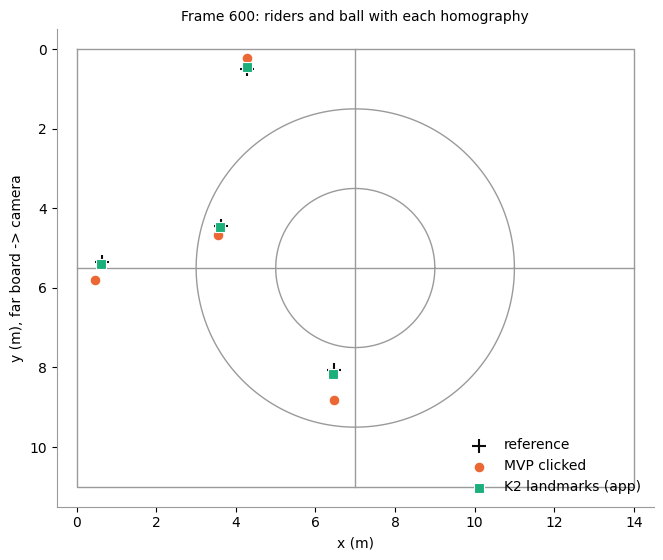

In [27]:
mp = build_map_points(load_detections())
riders = mp[mp.kind == "rider"][["px", "py"]].to_numpy()
true_pos = to_m(H_REF, riders)
for name, H in [("MVP clicked", H_MANUAL), (f"{FINAL} (app)", H_AUTO)]:
    shift = np.linalg.norm(to_m(H, riders) - true_pos, axis=1)
    print(f"{name:22s} rider dots off by: mean {shift.mean():.2f} m, 95th percentile {np.percentile(shift, 95):.2f} m")

frame = 600
one = mp[mp.frame == frame]
fig, ax = plt.subplots(figsize=(8, 6.2))
for line in court_lines():
    ax.plot(line[:, 0], line[:, 1], color="#9a9a9a", lw=1)
for name, H, color, marker in [("reference", H_REF, "#0b0b0b", "+"), ("MVP clicked", H_MANUAL, "#eb6834", "o"),
                               (f"{FINAL} (app)", H_AUTO, COLORS[FINAL], "s")]:
    p = to_m(H, one[["px", "py"]].to_numpy())
    ax.scatter(p[:, 0], p[:, 1], s=90 if marker == "+" else 60, color=color, marker=marker, label=name, zorder=3,
               linewidths=1.5 if marker == "+" else 0.8, edgecolors=None if marker == "+" else "white")
ax.set_xlim(-0.5, 14.5); ax.set_ylim(11.5, -0.5); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m), far board -> camera"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Frame {frame}: riders and ball with each homography", fontsize=10)
plt.show()


- The app's homography uses 13 of the 14 landmarks: RANSAC left out `inner_circle_far` (0.43 m from where the others put it), the landmark riders cover most (section 12.1). The landmarks it used are 0.1-7 px from the reference labels.
- Over the whole court it is off by **0.07 m** on average and **0.19 m** at worst, against 0.52 m and 1.63 m for the clicked points. The clicked homography gets worse towards the camera (the near-board problem of section 4); ours stays flat, also behind the near board (y > 9.5 m) where it extrapolates.
- **Held out:** from 30 validation frames only, 0.14 m. That is the honest number for frames the model never trained on; the app's 0.07 m partly comes from training frames.
- **One frame or many:** a single frame gives 0.13 m on average, but anything from 0.04 to 0.62 m depending on which landmarks the riders cover. The median over 30 frames brings it to 0.07 m.
- **On the minimap** the rider dots go from 0.48 m off (95% within 1.06 m) to 0.05 m off (95% within 0.14 m). In frame 600 the clicked homography puts the rider nearest the camera about 0.7 m too close to the camera.

## 12. Error analysis of the final model

### 12.1 Which landmarks are hard?

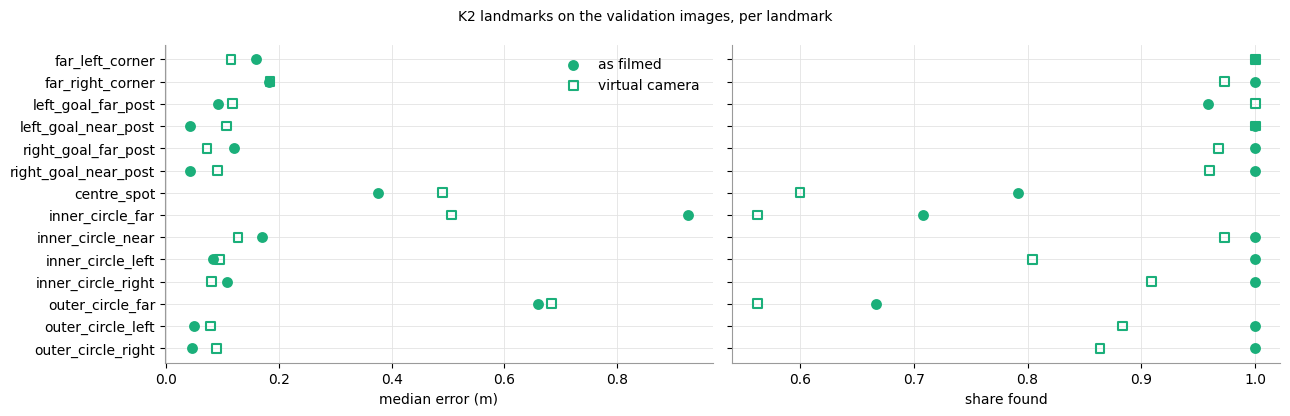

In [28]:
k = kpt_eval[FINAL]
k_in = k[k.in_picture]
per_landmark = (k_in.groupby(["landmark", "kind"]).agg(found=("found", "mean"), error_m=("error_m", "median"))
                .unstack("kind").reindex(NAMES))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y = np.arange(len(NAMES))
for ax, metric, label in [(axes[0], "error_m", "median error (m)"), (axes[1], "found", "share found")]:
    for kind, marker, face in [("as filmed", "o", COLORS[FINAL]), ("virtual camera", "s", "none")]:
        ax.scatter(per_landmark[(metric, kind)], y, marker=marker, s=40, facecolors=face, edgecolors=COLORS[FINAL],
                   linewidths=1.5, label=kind, zorder=3)
    ax.set_xlabel(label)
axes[0].set_yticks(y, NAMES); axes[0].invert_yaxis(); axes[0].legend(frameon=False)
fig.suptitle(f"{FINAL} on the validation images, per landmark", fontsize=10)
plt.tight_layout(); plt.show()

In [29]:
covered = (k_in[k_in.found].groupby(["kind", "hidden"]).error_m
           .agg(median="median", p90=lambda s: s.quantile(0.9), landmarks="size").round(3))
covered.index = covered.index.set_names(["val images", "inside a rider/bike box"])
covered

median    p90  landmarks
val images     inside a rider/bike box                          
as filmed      False                     0.068  0.212        228
               True                      0.269  0.991         87
virtual camera False                     0.085  0.222        336
               True                      0.215  0.774        123

Eleven landmarks are found in (nearly) every frame as filmed and in at least 80% of the virtual views, and are within about 0.2 m. Three are weak: the **centre spot**, the **inner circle's far point** and the **outer circle's far point**. They are found in only 56-79% of the views, with median errors of 0.4-0.9 m. Three things work against them:
1. riders cross the middle of the court all the time, so these landmarks are often covered;
2. they lie towards the far side, where one pixel at the model's 640 px input (~5 px of the frame) is about 0.2 m of depth;
3. the outer circle's far point has no mark of its own, only a gently curving line.

The table confirms the cover effect: landmarks inside a rider or bike box are 2.5-4 times less precise (median 0.27 vs 0.07 m on the frames as filmed). In the app, RANSAC and the median over 30 frames deal with it: `inner_circle_far` was left out of the fit.

### 12.2 Which camera views are hard?

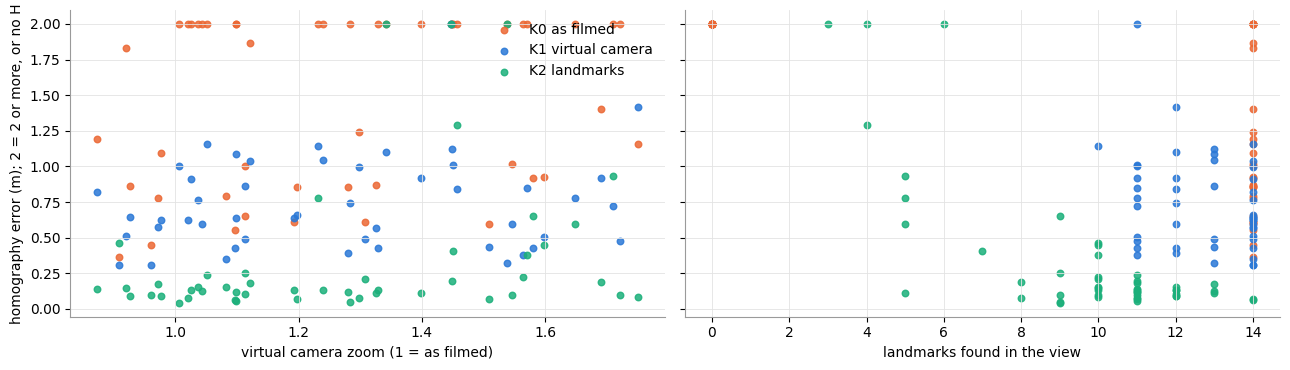

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for name in RUN_DIRS:
    e = img_eval[name]
    e = e[e.kind == "virtual camera"]
    axes[0].scatter(e.zoom, e.grid_mean_m.fillna(2).clip(upper=2), s=22, color=COLORS[name], label=name, alpha=0.85)
    axes[1].scatter(e.found, e.grid_mean_m.fillna(2).clip(upper=2), s=22, color=COLORS[name], label=name, alpha=0.85)
axes[0].set_xlabel("virtual camera zoom (1 = as filmed)"); axes[1].set_xlabel("landmarks found in the view")
axes[0].set_ylabel("homography error (m); 2 = 2 or more, or no H"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

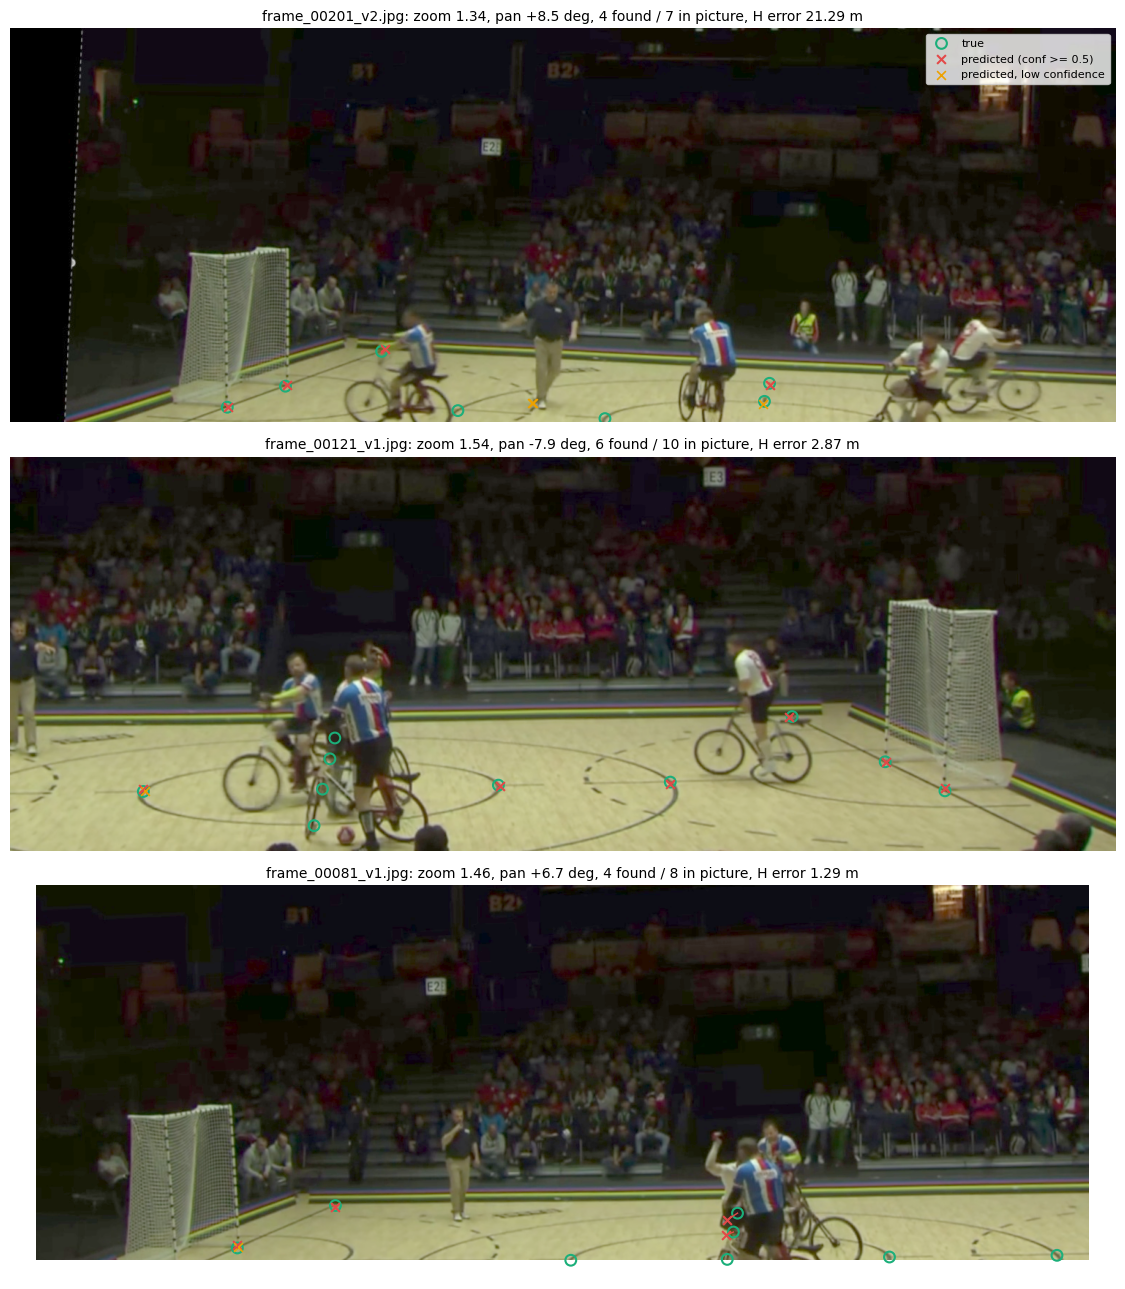

In [31]:
worst = img_eval[FINAL].sort_values("grid_mean_m", ascending=False).head(3)
fig, axes = plt.subplots(3, 1, figsize=(14, 13))
for ax, row in zip(axes, worst.itertuples()):
    r = val[val.image == row.image].iloc[0]
    image = cv2.imread(str(DATA / "images" / "val" / row.image))
    gt, vis, _ = ground_truth(r)
    xy, conf = keypoints_in_frame(FINAL_MODEL, image)
    gt = gt * [image.shape[1], image.shape[0]]
    ax.imshow(cv2.cvtColor(brighten(image), cv2.COLOR_BGR2RGB))
    ax.scatter(gt[vis > 0, 0], gt[vis > 0, 1], s=60, facecolors="none", edgecolors="#1baf7a", linewidths=1.5, label="true")
    ok = conf >= MIN_CONFIDENCE
    ax.scatter(xy[ok, 0], xy[ok, 1], s=40, marker="x", c="#e34948", linewidths=1.5, label="predicted (conf >= 0.5)")
    ax.scatter(xy[~ok & (conf > 0), 0], xy[~ok & (conf > 0), 1], s=40, marker="x", c="#eda100", linewidths=1.2,
               label="predicted, low confidence")
    for j in np.flatnonzero(ok & (vis > 0)):
        ax.plot([gt[j, 0], xy[j, 0]], [gt[j, 1], xy[j, 1]], color="#e34948", lw=1)
    ax.set_title(f"{row.image}: zoom {row.zoom:.2f}, pan {row.pan:+.1f} deg, {row.found} found / {row.in_picture} in "
                 f"picture, H error {row.grid_mean_m:.2f} m", fontsize=10)
    ax.axis("off")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

 K2's bad views have one thing in common: **few landmarks, badly spread.** Every view with an error above 0.75 m has 6 or fewer landmarks found; with 10 or more found, no K2 view is worse than 0.46 m.
- **Worst view (21 m):** 4 landmarks found, and three of them, the far left corner and the left goal's two posts, lie on one straight line (the end line). A homography needs 4 points of which no 3 are on a line. With 3 on a line the fit is nearly undetermined, so a tiny error turns into 21 m at the other end of the court.
- **The other two:** the zoomed-in camera shows about half the court and riders cover the centre landmarks, so the fit extrapolates over metres from a handful of points.
- The landmarks that *are* found sit on their true positions (circles and crosses coincide): the geometry is the problem, not the detections.

**Fix (next step, not done):** accept an `H` only when at least ~6 landmarks are used and they are not (nearly) on one or two lines; otherwise keep the last good `H`. For a moving camera the previous frame's `H` is a good fallback. For the static sample clip this does not happen: the app's `H` uses 13 landmarks.

## 13. Limits and next steps

- **One hall, one camera position.** The virtual camera covers pan, tilt, roll and zoom from the same spot. It does not cover a camera somewhere else (parallax), another hall, other lighting or other floor markings. The validation set is the same hall, so our numbers measure robustness to camera motion and riders, not to a new venue. *Next:* label landmarks on a few frames of another cycle-ball clip as a real test set.
- **The reference is our own measurement.** The labels are 3 cm off on average (10 cm at worst) and the goals and painted circles disagree by about 0.2 m, which we resolved by measuring the goals (section 3). Beyond y = 7.5 m there is no landmark, so the reference itself is extrapolated there.
- **Few or lined-up landmarks give a bad H** (section 12.2). *Next:* a validity check plus fallback.
- **Covered landmarks are missed** by K2, and the three middle landmarks are the weakest (section 12.1). *Next:* more training frames with riders in the middle; per-frame smoothing for a moving camera.
- **Resolution.** At 640 px the 2.8:1 frame leaves the court about 100 px tall at the model's input; one pixel is ~0.2 m of depth on the far side. K2's remaining noise (3-4 px of the frame) comes from that. *Next:* imgsz 960 or 1280 on a GPU (Colab), or feed the model only the strip of the frame with the court.
- **Training compromises.** K1 changed batch size mid-run (memory), stopped early at epoch 37, and K2 trained 50 epochs. Every model was trained once (one seed), so unlike notebook 07 we have no estimate of seed noise. The differences we draw conclusions from (0.55 vs 0.12 m, squeeze 8% vs 0%) are far larger than seed noise usually is; small differences are not established.
- **Approximations.** "Covered" means inside a detector box, which is larger than the rider. The virtual camera's focal length is a rough estimate. The RANSAC threshold (0.3 m) and confidence cut (0.5) were not tuned.
- **Planar assumption (unchanged from the MVP).** A ball in the air is not on the floor, so its map position stays approximate whatever the homography.

